## KNN: iNat Bees

Freeze backbone from ResNet trained in `ResNet_Train.ipynb` and transform prototype images in the latent space of the CNN.

The explanation will then be formulated on the basis of the $k$ nearest prototypes.

In [1]:
!pwd
import sys, os
sys.path.append('./wingbeats/')

/mnt/KInsektDaten/teo


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import glob, pickle, cv2
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import log_loss
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import label_ranking_average_precision_score as lrap
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from beexplainable.beexplainable.utils import metafile_readers as mr
from wingbeats import modelling as wm # for building simple classifiers

No module named 'nltk'


In [3]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2024-03-13 14:54:03.987419: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-03-13 14:54:04.583800: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 47125 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [4]:
spec_subfolder = '5_species/'
metafolder = './beexplainable/metafiles/Bees_Christian/'
CONCEPTS_PATH = '../data/Wildbienen/Concepts_Bombus_vs_Andrena_StabDiff_insects/'
CLASSES_PATH = metafolder + spec_subfolder + '/classes.txt'
BEES_PATH = '../data/Wildbienen/Bees_Christian_masked_bbox/Whole/'

IMAGES_PATH = metafolder + 'images_5.txt'
IMAGES_LABELS_PATH = metafolder + spec_subfolder + 'image_class_labels.txt'
MODELS_PATH  = './beexplainable/models/'

### Load Test Images

In [5]:
batch_size = 64
img_height = img_width = 224

In [6]:
# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
file_ids_bees = list( img_dict.keys() )
y_true_bees   = list( img_label_dict.values() )
y_true_bees   = np.asarray(y_true_bees, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0
len(y_true_bees)

216

In [7]:
classes = list( mr.metafile_to_dict(CLASSES_PATH).values() )
classes

['Andrena_bicolor',
 'Andrena_flavipes',
 'Andrena_fulva',
 'Bombus_lucorum',
 'Bombus_pratorum']

In [8]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids_bees, list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, BEES_PATH),
                                          label)

2024-03-13 14:54:04.660845: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 47125 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [9]:
# Conversion to tf.Dataset
test_set = ps.parse_to_dataset(file_ids_bees, y_true_bees, parse_image_lab)
test_set = test_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
test_set = test_set.map(lambda x, y: (normalization_layer(x), y))

2024-03-13 14:54:06.032585: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


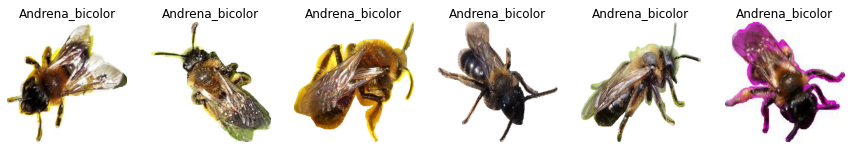

In [10]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = min(6, batch_size)
with tf.device('/CPU:0'):
    for images, labels in test_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(classes[labels[i].numpy()])
            plt.axis("off")
plt.show()

In [11]:
for image_batch, labels_batch in test_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

(64, 224, 224, 3)
tf.Tensor(0, shape=(), dtype=uint8)


2024-03-13 14:54:06.571136: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


#### Load Random Images

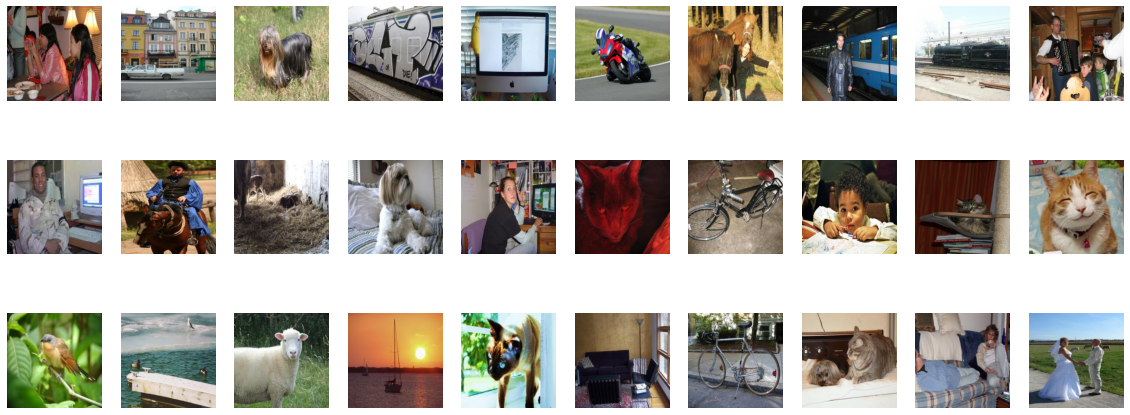

In [12]:
random_img_folder = '../data/broden1_224/images/pascal/'
input_size = img_height

random_imgs = os.listdir(random_img_folder)
random_imgs_filter = lambda f : all([rm not in f for rm in ['object', 'color', 'part']]) # only take 'natural' image

# Load same random images used for tcav fungi
with open('./beexplainable/metafiles/Fungi/raw/fungi_tcav_random.pickle', 'rb') as handle:
    files = pickle.load(handle)

random_dataset = [cv2.imread(random_img_folder+img)[...,::-1] for img in files]
random_dataset = [tf.image.resize(img, [img_width, img_height]) for img in random_dataset]
random_dataset = np.array([img/255.0 for img in random_dataset])

plt.figure(figsize = (20, 8))
for i in range(30):
    plt.subplot(3, 10, i+1)
    plt.imshow(random_dataset[i])
    plt.axis('off')

#### Load Prototype Images

In [13]:
# Store concepts, image paths and create label vector from subfolder names
concepts, concept_files, y_true_con = [], [], []
concept_subfolders = sorted( glob.glob(CONCEPTS_PATH + '*') )
for i in range(len(concept_subfolders)):
    # Add concept from subfolder base name
    concept = os.path.basename(concept_subfolders[i])
    concepts.append( concept )

    # Get image paths in current concept subfolder (there are .jpg and .png files)
    c_files = glob.glob(CONCEPTS_PATH + concept + '/*.jpg') + glob.glob(CONCEPTS_PATH + concept + '/*.png')
    concept_files += [c[len(CONCEPTS_PATH):] for c in c_files] # remove the constant path to the common dir.
    y_true_con += [i] * len(c_files)

concepts

['fuzzy_dark_orange', 'fuzzy_yellow_black_stripes', 'smooth_shiny_dark_brown']

In [14]:
# Define file ids (for consistency with the parsers in the pipeline)
# Note: the metafile readers return a Dict[str, str]
file_ids_con = [str(i) for i in range(1, len(y_true_con)+1)]

In [15]:
# Get dictionary of file IDs and file names
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids_con, concept_files),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, CONCEPTS_PATH),
                                          label)

In [16]:
# Conversion to tf.Dataset
concept_set = ps.parse_to_dataset(file_ids_con, y_true_con, parse_image_lab)
concept_set = concept_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
concept_set = concept_set.map(lambda x, y: (normalization_layer(x), y))

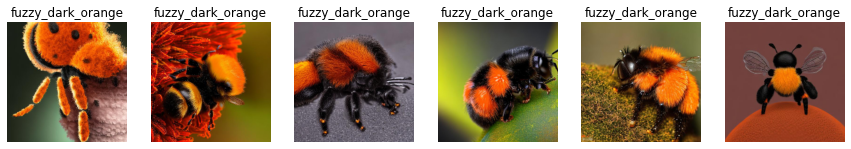

In [17]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = min(6, batch_size)
with tf.device('/CPU:0'):
    for images, labels in concept_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(concepts[labels[i].numpy()])
            plt.axis("off")
plt.show()

In [18]:
for image_batch, labels_batch in concept_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

(64, 224, 224, 3)
tf.Tensor(0, shape=(), dtype=int32)


### Load Model

In [19]:
# Define initial training and other model parameters
epochs, drop_rate = 10, 0.5
lr, reg = 1e-3, 1e-3 # parameters optimized in HPO notebook
in_shape = (img_width, img_height, 3)

constructor, out_shape =  wm.build_simple_classifier, len(classes)
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy']

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
input_form = 'masked_bbox' # raw, masked, bbox, masked_bbox
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_' + input_form + '_5spec_2'

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

In [20]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(MODELS_PATH + 'all/' + spec_subfolder + model_name + '/' + model_name + '.h5',
                   by_name = True, skip_mismatch = True)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

### XAI: Predict Prototypes

In [21]:
# Concatenate concepts and random dataset
con_rand_set = []
for img, _ in concept_set.unbatch().as_numpy_iterator():
    con_rand_set.append(img)
con_rand_set = np.asarray(con_rand_set)
con_rand_set = np.concatenate((con_rand_set, random_dataset))
print(con_rand_set.shape)

y_true_con_rand = np.concatenate((y_true_con, np.array([len(concepts)]*len(random_dataset))))
print(y_true_con_rand.shape)

(1090, 224, 224, 3)
(1090,)


In [22]:
# Extract features of mixed sets
res_con_rand = cnn.resnet.predict(con_rand_set)
tf.shape(res_con_rand)

2024-03-13 14:54:15.252957: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2024-03-13 14:54:15.735259: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-13 14:54:15.736328: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-13 14:54:15.736340: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2024-03-13 14:54:15.737418: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-13 14:54:15.737588: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


<tf.Tensor: shape=(2,), dtype=int32, numpy=array([1090, 2048], dtype=int32)>

In [23]:
# Extract features for all test samples
test_activations = cnn.resnet.predict(test_set)
test_activations.shape

(216, 2048)

#### Multiple random partitions, one kNN for all concepts

In [24]:
# One-hot-encode the concepts
concept_basis = OneHotEncoder().fit_transform([[0], [1], [2]]).toarray()
# A. bicolor:  orange + brown | B. lucorum:  yellow
# A. flavipes: brown          | B. pratorum: orange + yellow
# A. fulva:    orange
lookup_cls_concepts = [concept_basis[0] + concept_basis[2],
                       concept_basis[2],
                       concept_basis[0],
                       concept_basis[1],
                       concept_basis[0] + concept_basis[1]]
lookup_cls_concepts[0]

array([1., 0., 1.])

In [25]:
# Fit multiple kNNs for multiple random partitions of the random set
k = 18 # optimal k found in ResNet_Cluster_Concepts_Optim_k.ipynb
num_parts = 100 # how often to randomly select subsets of the random set
knn_probs = np.zeros((len(test_activations), len(concepts)+1)) # matrix of aggregated probs for every sample and every concept
for i in range(num_parts):
    # Select random indexes (starting after last concept img index)
    random_ids = np.random.choice( np.arange(len(file_ids_con), len(con_rand_set)), 30,
                                   replace = False)

    # Overall index vector (concept indexes, then current random subset indexes)
    con_rand_ids = np.concatenate( (np.arange(len(file_ids_con)), random_ids) )

    # Fit a kNN on current partition
    neigh = KNeighborsClassifier(n_neighbors=k)
    neigh.fit(res_con_rand[con_rand_ids], y_true_con_rand[con_rand_ids])

    # Predict concepts for all test vectors
    knn_probs += neigh.predict_proba(test_activations)

# Average over number of random partitions
knn_probs /= num_parts
knn_probs

array([[1.66666667e-01, 1.02222222e-01, 5.82777778e-01, 1.48333333e-01],
       [2.16666667e-02, 5.55555556e-02, 8.30000000e-01, 9.27777778e-02],
       [4.33333333e-02, 5.55555556e-02, 7.95555556e-01, 1.05555556e-01],
       [5.55555556e-02, 9.33333333e-02, 5.26111111e-01, 3.25000000e-01],
       [0.00000000e+00, 5.55555556e-02, 8.05555556e-01, 1.38888889e-01],
       [5.55555556e-02, 5.55555556e-02, 7.19444444e-01, 1.69444444e-01],
       [1.98333333e-01, 1.11111111e-01, 5.68888889e-01, 1.21666667e-01],
       [1.66666667e-01, 2.80000000e-01, 4.28333333e-01, 1.25000000e-01],
       [1.10555556e-01, 6.50000000e-02, 7.28333333e-01, 9.61111111e-02],
       [7.00000000e-02, 1.11111111e-01, 4.76666667e-01, 3.42222222e-01],
       [1.10000000e-01, 1.10555556e-01, 6.12222222e-01, 1.67222222e-01],
       [0.00000000e+00, 5.55555556e-02, 8.07222222e-01, 1.37222222e-01],
       [5.55555556e-02, 5.55555556e-02, 8.52777778e-01, 3.61111111e-02],
       [5.55555556e-02, 1.09444444e-01, 6.06111111e

##### Offline metrics and mean scores per class

In [26]:
probs_cls_dict = {}
for c in classes:
    knn_probs_cls = knn_probs[np.where(y_true_bees == classes.index(c)), :-1][0] # leave random component out
    probs_cls_dict[c] = np.mean(knn_probs_cls, axis=0)

    # Get true concept(s) based on true class
    true_con = lookup_cls_concepts[classes.index(c)]

    bce, cos_sim = [], []
    for p in knn_probs_cls:
        # Compute binary cross entropy
        bce.append( log_loss(true_con, p) )
        # Compute cosine sim.
        cos_sim.append( cosine_similarity(true_con.reshape(1, -1), p.reshape(1, -1))[0][0] )

    # Rank correlation
    rank = lrap(np.tile(true_con, (len(knn_probs_cls),1)), knn_probs_cls)

    print(c)
    print('BCE:')
    print(str(np.round(np.mean(bce),4)) + '+/-' + str(np.round(np.std(bce),4)))
    print('Cosine Similarity:')
    print(str(np.round(np.mean(cos_sim),4)) + '+/-' + str(np.round(np.std(cos_sim),4)))
    print('Rank Correlation:')
    print(rank)
    print()

Andrena_bicolor
BCE:
2.7853+/-3.9435
Cosine Similarity:
0.7831+/-0.0763
Rank Correlation:
0.8777777777777777

Andrena_flavipes
BCE:
0.1406+/-0.0251
Cosine Similarity:
0.9926+/-0.0043
Rank Correlation:
1.0

Andrena_fulva
BCE:
0.4892+/-0.2474
Cosine Similarity:
0.7373+/-0.2118
Rank Correlation:
0.8555555555555556

Bombus_lucorum
BCE:
0.4085+/-0.2234
Cosine Similarity:
0.7929+/-0.2027
Rank Correlation:
0.8663194444444443

Bombus_pratorum
BCE:
1.0763+/-0.2671
Cosine Similarity:
0.7639+/-0.1412
Rank Correlation:
0.8361111111111108



In [28]:
probs_cls_dict

{'Andrena_bicolor': array([0.08896296, 0.083     , 0.67494444]),
 'Andrena_flavipes': array([0.03955556, 0.07387037, 0.73918519]),
 'Andrena_fulva': array([0.42383333, 0.06088889, 0.34185185]),
 'Bombus_lucorum': array([0.20703704, 0.51249421, 0.17983218]),
 'Bombus_pratorum': array([0.14481481, 0.44811111, 0.21596296])}

In [29]:
probs_con_dict = {}
for c in concepts:
    probs_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        probs_con_dict[c][i] = probs_cls_dict[classes[i]][concepts.index(c)]
probs_con_dict

{'fuzzy_dark_orange': array([0.08896296, 0.03955556, 0.42383333, 0.20703704, 0.14481481]),
 'fuzzy_yellow_black_stripes': array([0.083     , 0.07387037, 0.06088889, 0.51249421, 0.44811111]),
 'smooth_shiny_dark_brown': array([0.67494444, 0.73918519, 0.34185185, 0.17983218, 0.21596296])}

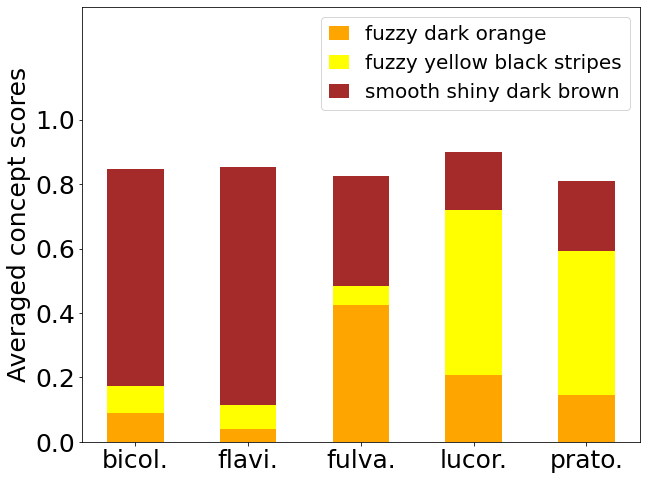

In [30]:
# Multiple random partitions
con_colors = ['orange', 'yellow', 'brown']
fontsize = 25
width = 0.5
plt.figure(figsize=(10,8))
bottom = np.zeros(len(classes))
for i, (con, probs) in enumerate(probs_con_dict.items()):
    plt.bar(classes, probs, width=width, label=con, bottom=bottom, color=con_colors[i])
    bottom += probs

plt.ylim(0.0, 1.35)
plt.legend([c.replace('_', ' ') for c in concepts], loc='upper right', fontsize=fontsize-5, handlelength=1.0)
plt.xticks(np.arange(0.0, 10*width, width*2),
           [c.split('_')[1][:5]+'.' for c in classes],
           fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylabel('Averaged concept scores', fontsize=fontsize)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/mean_bees_knn_stacked.png', bbox_inches='tight')
plt.show()

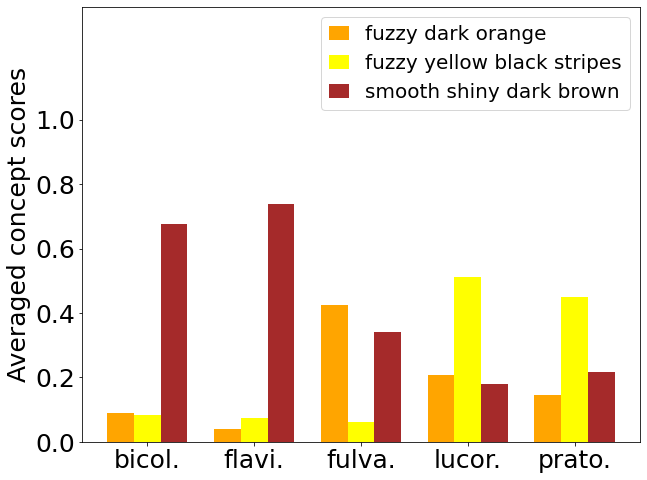

In [31]:
x = np.arange(len(classes))  # the label locations
width = 0.25  # the width of the bars
multiplier = 0
fontsize = 25
con_colors = ['orange', 'yellow', 'brown']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i, (con, freq) in enumerate(probs_con_dict.items()):
   offset = width * multiplier
   rects = plt.bar(x + offset, freq, width, label=con, color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, freq):
       if height == 0:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '$\diamond$', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x+width,
           [c.split('_')[1][:5]+'.' for c in classes],
           fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylim(0.0, 1.35)
plt.ylabel('Averaged concept scores', fontsize=fontsize)
plt.legend([c.replace('_', ' ') for c in concepts], loc='upper right', fontsize=fontsize-5, handlelength=1.0)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/mean_bees_knn.png', bbox_inches='tight')
plt.show()

##### Frequency of dominant prototypes

In [ ]:
# Count how often each concept is predicted as dominant concept (knn_prob == max_prob)
sig_cls_dict = {}
for c in classes:
    cls_ind = np.where(y_true_bees == classes.index(c))
    sig_cls_dict[c] = np.count_nonzero(knn_probs[cls_ind, :len(concepts)][0] ==
                                       np.tile(np.max(knn_probs[cls_ind, :len(concepts)][0], axis=1),
                                               (len(concepts),1)).T,
                                                axis=0) / len(cls_ind[0])
sig_cls_dict

In [31]:
sig_con_dict = {}
for c in concepts:
    sig_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        sig_con_dict[c][i] = sig_cls_dict[classes[i]][concepts.index(c)]
sig_con_dict

{'fuzzy_dark_orange': array([0.1       , 0.03333333, 0.86666667, 0.22916667, 0.1       ]),
 'fuzzy_yellow_black_stripes': array([0.03333333, 0.1       , 0.03333333, 0.78125   , 0.86666667]),
 'smooth_shiny_dark_brown': array([0.86666667, 0.93333333, 0.1       , 0.17708333, 0.1       ])}

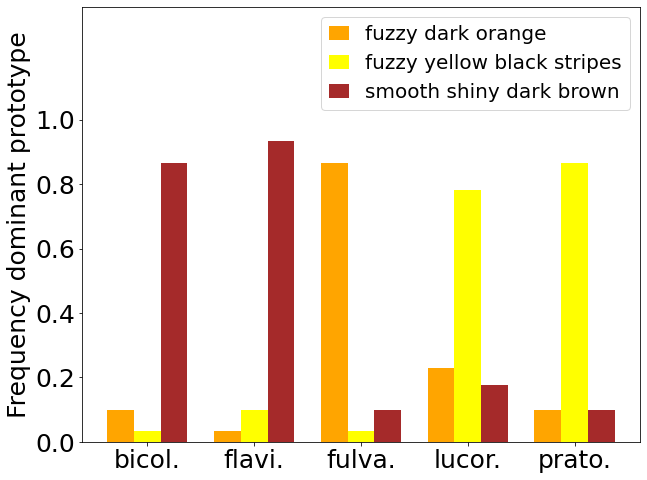

In [32]:
x = np.arange(len(classes))  # the label locations
width = 0.25  # the width of the bars
fontsize = 25
multiplier = 0
con_colors = ['orange', 'yellow', 'brown']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i, (con, freq) in enumerate(sig_con_dict.items()):
   offset = width * multiplier
   rects = plt.bar(x + offset, freq, width, label=con, color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, freq):
       if height == 0:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '*', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x+width,
           [c.split('_')[1][:5]+'.' for c in classes],
           fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylabel('Frequency dominant prototype', fontsize=fontsize)
plt.ylim(0.0, 1.35)
plt.legend([c.replace('_', ' ') for c in concepts], loc='upper right', fontsize=fontsize-5, handlelength=1.0)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/bees_knn_freq.png', bbox_inches='tight')
plt.show()

#### Multiple random partitions, one kNN per concept

In [24]:
# One-hot-encode the concepts
concept_basis = OneHotEncoder().fit_transform([[0], [1], [2]]).toarray()
# A. bicolor:  orange + brown | B. lucorum:  yellow
# A. flavipes: brown          | B. pratorum: orange + yellow
# A. fulva:    orange
lookup_cls_concepts = [concept_basis[0] + concept_basis[2],
                       concept_basis[2],
                       concept_basis[0],
                       concept_basis[1],
                       concept_basis[0] + concept_basis[1]]
lookup_cls_concepts[0]

array([1., 0., 1.])

In [25]:
# Fit multiple kNNs for multiple random partitions of thre random set
k = 28 # optimal k found in ResNet_Cluster_Concepts_Optim_k.ipynb
num_parts = 100 # how often to randomly select subsets of the random set
knn_probs = np.zeros((len(test_activations), len(concepts))) # matrix of aggregated probs for every sample and every concept
for i in range(num_parts):

    # Select random indexes (starting after last concept img index)
    random_ids = np.random.choice( np.arange(len(file_ids_con), len(con_rand_set)), 30,
                                   replace = False)

    # Fit a kNN on current partition for every concept
    for j in range(len(concepts)):
        # Overall index vector (concept indexes, then current random subset indexes)
        con_ids = np.where(np.asarray(y_true_con) == j)[0]
        con_rand_ids = np.concatenate( (con_ids, random_ids) )

        neigh = KNeighborsClassifier(n_neighbors=k)
        neigh.fit(res_con_rand[con_rand_ids], y_true_con_rand[con_rand_ids])

        # Predict concepts for all test vectors
        knn_probs[:, j] += neigh.predict_proba(test_activations)[:, 0] # 2nd prob. is for random

# Average over number of random partitions
knn_probs /= num_parts
knn_probs

array([[0.35107143, 0.34535714, 0.63678571],
       [0.31178571, 0.33107143, 0.73785714],
       [0.35178571, 0.33428571, 0.76357143],
       [0.34964286, 0.34535714, 0.58392857],
       [0.26607143, 0.32142857, 0.77285714],
       [0.29892857, 0.32321429, 0.69357143],
       [0.34142857, 0.33178571, 0.62357143],
       [0.42285714, 0.51607143, 0.66035714],
       [0.30535714, 0.33821429, 0.80607143],
       [0.33535714, 0.35285714, 0.56107143],
       [0.34392857, 0.34571429, 0.64821429],
       [0.29785714, 0.32464286, 0.78964286],
       [0.31214286, 0.41821429, 0.84964286],
       [0.31107143, 0.31428571, 0.60571429],
       [0.34107143, 0.32178571, 0.81035714],
       [0.30892857, 0.30392857, 0.76678571],
       [0.37035714, 0.35178571, 0.83642857],
       [0.29464286, 0.38964286, 0.6575    ],
       [0.42142857, 0.32142857, 0.55678571],
       [0.245     , 0.37785714, 0.84035714],
       [0.35035714, 0.3375    , 0.66678571],
       [0.33214286, 0.34857143, 0.59035714],
       [0.

##### Offline metrics and mean scores per class

In [27]:
probs_cls_dict = {}
for c in classes:
    knn_probs_cls = knn_probs[np.where(y_true_bees == classes.index(c))]
    probs_cls_dict[c] = np.mean(knn_probs_cls, axis=0)

    # Get true concept(s) based on true class
    true_con = lookup_cls_concepts[classes.index(c)]

    bce, cos_sim = 0.0, 0.0
    for p in knn_probs_cls:
        # Compute binary cross entropy
        bce += log_loss(true_con, p)
        # Compute cosine sim.
        cos_sim += cosine_similarity(true_con.reshape(1, -1), p.reshape(1, -1))[0][0]

    print(c)
    print('BCE:')
    print(bce/len(knn_probs_cls));
    print('Cosine Similarity:')
    print(cos_sim/len(knn_probs_cls))
    print()

Andrena_bicolor
BCE:
0.6296000383886198
Cosine Similarity:
0.8564736049939374

Andrena_flavipes
BCE:
0.31603916046084063
Cosine Similarity:
0.8790833344169753

Andrena_fulva
BCE:
0.6788610554708254
Cosine Similarity:
0.5826469701429282

Bombus_lucorum
BCE:
0.7381414094466642
Cosine Similarity:
0.6469139211880867

Bombus_pratorum
BCE:
0.7810204652633531
Cosine Similarity:
0.7621147448849116



In [28]:
probs_cls_dict

{'Andrena_bicolor': array([0.33111905, 0.34542857, 0.71207143]),
 'Andrena_flavipes': array([0.23908333, 0.34778571, 0.78330952]),
 'Andrena_fulva': array([0.49991667, 0.35435714, 0.58539286]),
 'Bombus_lucorum': array([0.51030506, 0.68812128, 0.62032366]),
 'Bombus_pratorum': array([0.39358333, 0.56047619, 0.55211905])}

In [29]:
probs_con_dict = {}
for c in concepts:
    probs_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        probs_con_dict[c][i] = probs_cls_dict[classes[i]][concepts.index(c)]/len(concepts)
probs_con_dict

{'fuzzy_dark_orange': array([0.11037302, 0.07969444, 0.16663889, 0.17010169, 0.13119444]),
 'fuzzy_yellow_black_stripes': array([0.11514286, 0.11592857, 0.11811905, 0.22937376, 0.1868254 ]),
 'smooth_shiny_dark_brown': array([0.23735714, 0.26110317, 0.19513095, 0.20677455, 0.18403968])}

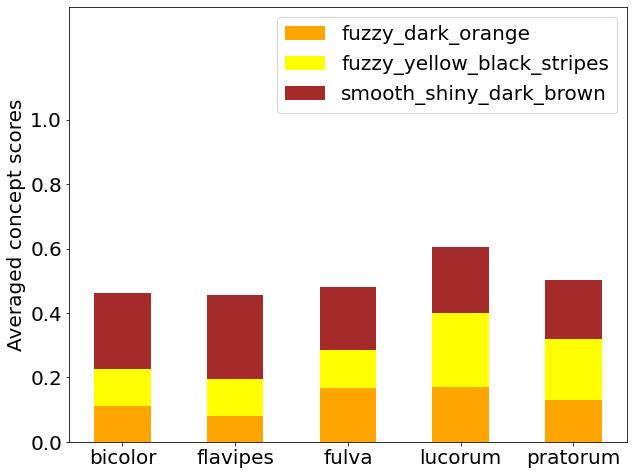

In [30]:
# Multiple random partitions
con_colors = ['orange', 'yellow', 'brown']
fontsize = 20
width = 0.5
plt.figure(figsize=(10,8))
bottom = np.zeros(len(classes))
for i, (con, probs) in enumerate(probs_con_dict.items()):
    plt.bar(classes, probs, width=width, label=con, bottom=bottom, color=con_colors[i])
    bottom += probs

plt.ylim(0.0, 1.35)
plt.legend(loc='upper right', fontsize=fontsize)
plt.xticks(np.arange(0.0, 10*width, width*2),
           [c.split('_')[1] for c in classes],
           fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylabel('Averaged concept scores', fontsize=fontsize)
#plt.savefig('./beexplainable/figures/knn_vs_tcav/mean_bees_knn_multilabel.png', bbox_inches='tight')
plt.show()

In [31]:
probs_con_dict = {}
for c in concepts:
    probs_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        probs_con_dict[c][i] = probs_cls_dict[classes[i]][concepts.index(c)]
probs_con_dict

{'fuzzy_dark_orange': array([0.33111905, 0.23908333, 0.49991667, 0.51030506, 0.39358333]),
 'fuzzy_yellow_black_stripes': array([0.34542857, 0.34778571, 0.35435714, 0.68812128, 0.56047619]),
 'smooth_shiny_dark_brown': array([0.71207143, 0.78330952, 0.58539286, 0.62032366, 0.55211905])}

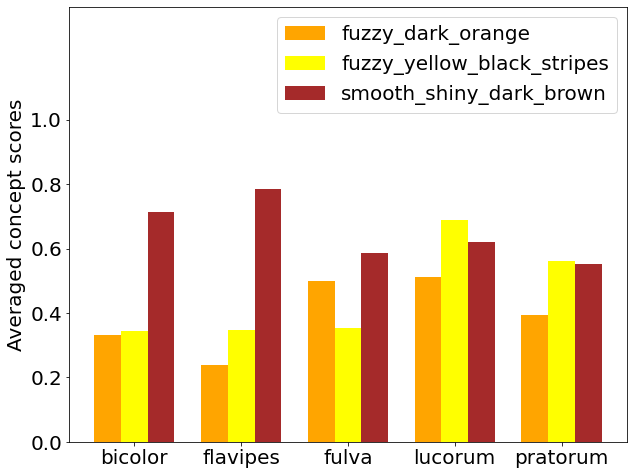

In [33]:
x = np.arange(len(classes))  # the label locations
width = 0.25  # the width of the bars
fontsize = 20
multiplier = 0
con_colors = ['orange', 'yellow', 'brown']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i, (con, freq) in enumerate(probs_con_dict.items()):
   offset = width * multiplier
   rects = plt.bar(x + offset, freq, width, label=con, color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, freq):
       if height == 0:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '$\diamond$', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x+width,
           [c.split('_')[1] for c in classes],
           fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylabel('Averaged concept scores', fontsize=fontsize)
plt.ylim(0.0, 1.35)
plt.legend(loc='upper right', fontsize=fontsize)
#plt.savefig('./beexplainable/figures/knn_vs_tcav/bees_knn_freq_multilabel.png', bbox_inches='tight')
plt.show()

##### Frequency of dominant prototypes

In [39]:
# Count how often each concept is predicted as dominant concept (knn_prob == max_prob)
sig_cls_dict = {}
for c in classes:
    cls_ind = np.where(y_true_bees == classes.index(c))
    sig_cls_dict[c] = np.count_nonzero(knn_probs[cls_ind, :len(concepts)][0] ==
                                       np.tile(np.max(knn_probs[cls_ind, :len(concepts)][0], axis=1),
                                               (len(concepts),1)).T,
                                                axis=0) / len(cls_ind[0])
sig_cls_dict

{'Andrena_bicolor': array([0.1       , 0.03333333, 0.9       ]),
 'Andrena_flavipes': array([0.        , 0.06666667, 0.93333333]),
 'Andrena_fulva': array([0.86666667, 0.03333333, 0.13333333]),
 'Bombus_lucorum': array([0.29166667, 0.91666667, 0.11458333]),
 'Bombus_pratorum': array([0.06666667, 0.9       , 0.13333333])}

In [40]:
sig_con_dict = {}
for c in concepts:
    sig_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        sig_con_dict[c][i] = sig_cls_dict[classes[i]][concepts.index(c)]
sig_con_dict

{'fuzzy_dark_orange': array([0.1       , 0.        , 0.86666667, 0.29166667, 0.06666667]),
 'fuzzy_yellow_black_stripes': array([0.03333333, 0.06666667, 0.03333333, 0.91666667, 0.9       ]),
 'smooth_shiny_dark_brown': array([0.9       , 0.93333333, 0.13333333, 0.11458333, 0.13333333])}

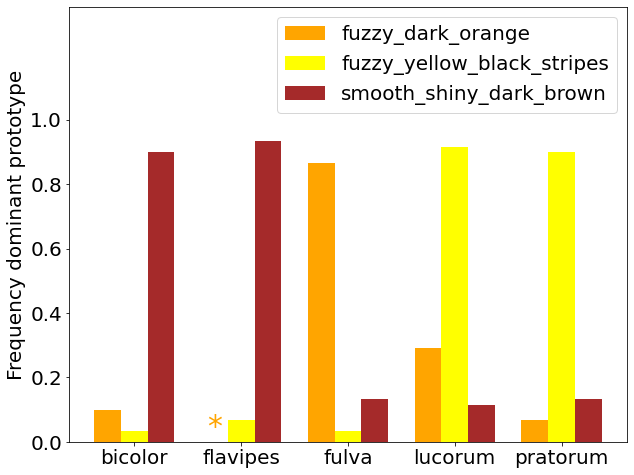

In [41]:
x = np.arange(len(classes))  # the label locations
width = 0.25  # the width of the bars
fontsize = 20
multiplier = 0
con_colors = ['orange', 'yellow', 'brown']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i, (con, freq) in enumerate(sig_con_dict.items()):
   offset = width * multiplier
   rects = plt.bar(x + offset, freq, width, label=con, color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, freq):
       if height == 0:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '*', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x+width,
           [c.split('_')[1] for c in classes],
           fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylabel('Frequency dominant prototype', fontsize=fontsize)
plt.ylim(0.0, 1.35)
plt.legend(loc='upper right', fontsize=fontsize)
plt.savefig('./beexplainable/figures/knn_vs_tcav/bees_knn_freq_multilabel.png', bbox_inches='tight')
plt.show()